In [1]:
# 1. IMPORTACIÓN DE LIBRERÍAS
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configuración visual
sns.set_theme(style="whitegrid", palette="muted")

In [3]:
# 2. CARGA DE DATOS Y ELIMINACIÓN DE VARIABLES
# Cargar el archivo original
dfRehab = pd.read_csv('rehabilitation_movement_dataset.csv')

# Variables candidatas a descartar identificadas previamente
variables_a_descartar = [
    'Quaternion_z', 
    'Quaternion_w', 
    'Age (yrs)',
    'Quaternion_x',
    'Accel_Y (m/s²)'
]

# Eliminar las variables del DataFrame
df_limpio = dfRehab.drop(columns=variables_a_descartar)

print(f"Columnas originales: {dfRehab.shape[1]}")
print(f"Columnas tras el descarte: {df_limpio.shape[1]}")

# Guardar el nuevo dataset optimizado
df_limpio.to_csv('rehabilitation_dataset_optimizado.csv', index=False)
print("\n¡Dataset optimizado guardado con éxito!")

Columnas originales: 33
Columnas tras el descarte: 28

¡Dataset optimizado guardado con éxito!


In [5]:
# 3. SELECCIÓN DE CARACTERÍSTICAS Y ETIQUETAS
# Usamos el dataset limpio
variable_objetivo = 'Performance_Label'

# Excluimos variables no predictivas que aún queden en el dataset limpio
columnas_excluidas_base = [
    'Timestamp (s)',
    'Participant_ID',
    'Gender',
    'Sensor_ID',
    'Body_Segment',
    'Obesity_Class',
    'Deviation_Level',
    'Performance_Label',
    'Feedback_Action',
]

X = df_limpio.drop(
    columns=[col for col in columnas_excluidas_base if col in df_limpio.columns]
)
y = df_limpio[variable_objetivo]

print('Dimensiones de X (Predictoras limpias):', X.shape)
print('Dimensiones de y (Objetivo):', y.shape)

Dimensiones de X (Predictoras limpias): (3000, 19)
Dimensiones de y (Objetivo): (3000,)


In [6]:
# 4. DIVISIÓN DE DATOS Y ESCALAMIENTO
# División en entrenamiento y prueba[cite: 1]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Escalamiento (Obligatorio para SVC)[cite: 1]
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Conjunto de entrenamiento escalado:', X_train_scaled.shape)
print('Conjunto de prueba escalado:', X_test_scaled.shape)

Conjunto de entrenamiento escalado: (2400, 19)
Conjunto de prueba escalado: (600, 19)


In [7]:
# 5. ENTRENAMIENTO DEL MODELO SVC
# Usamos kernel RBF con los hiperparámetros base[cite: 1]
modelo_svc = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

modelo_svc.fit(X_train_scaled, y_train)
print('¡El modelo SVC se entrenó correctamente con los datos optimizados!')

¡El modelo SVC se entrenó correctamente con los datos optimizados!


Exactitud (Accuracy): 0.9950

Reporte de Clasificación:
                  precision    recall  f1-score   support

       Deviation       1.00      0.99      0.99       200
         Optimal       1.00      1.00      1.00       200
Slight Deviation       0.99      0.99      0.99       200

        accuracy                           0.99       600
       macro avg       1.00      0.99      0.99       600
    weighted avg       1.00      0.99      0.99       600



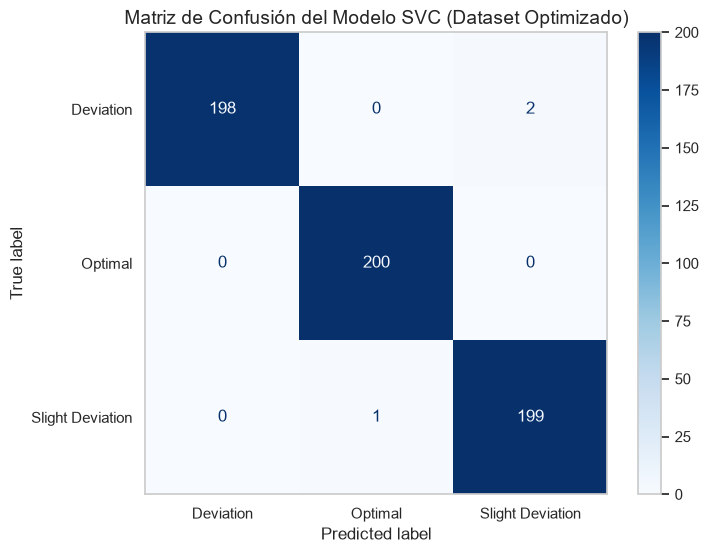

In [8]:
# 6. EVALUACIÓN Y RESULTADOS VISUALES
y_pred = modelo_svc.predict(X_test_scaled)

print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}\n")
print('Reporte de Clasificación:')
print(classification_report(y_test, y_pred, target_names=modelo_svc.classes_.astype(str)))

# Matriz de confusión visual con Seaborn/Matplotlib
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_svc.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusión del Modelo SVC (Dataset Optimizado)', fontsize=14)
plt.grid(False)
plt.show()